In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

<h1 style="color:gray">Data Load: Load the dataset into a dataframe</h1>

In [2]:
df = pd.read_csv("diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

<p>• No any null values found</p>

In [4]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


<p>
    • According to the graph above, the columns <b>Glucose, BloodPressure, SkinThickness, Insulin, and BMI</b> contain records with values of 0. Since these values are medically impossible for a living person, they will be treated as missing values and replaced with null (NaN) values.
</p>

In [5]:
df_clean = df.copy()

invalid_zero_columns = [
    "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"
]

df_clean[invalid_zero_columns] = (
    df_clean[invalid_zero_columns].replace(0, np.nan)
)

In [6]:
df_clean.isnull().sum()

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

In [7]:
df_clean.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50,1
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31,0
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


In [8]:
df_clean.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,763.000000,733.000000,541.000000,394.000000,757.000000,768.000000,768.000000,768.000000
mean,3.845052,121.686763,72.405184,29.153420,155.548223,32.457464,0.471876,33.240885,0.348958
std,3.369578,30.535641,12.382158,10.476982,118.775855,6.924988,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,64.000000,22.000000,76.250000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,29.000000,125.000000,32.300000,0.372500,29.000000,0.000000
75%,6.000000,141.000000,80.000000,36.000000,190.000000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [9]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   763 non-null    float64
 2   BloodPressure             733 non-null    float64
 3   SkinThickness             541 non-null    float64
 4   Insulin                   394 non-null    float64
 5   BMI                       757 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(6), int64(3)
memory usage: 54.1 KB


In [10]:
df_clean.shape

(768, 9)

<h1 style="color:gray">Data Exploration & Outlier Removal</h1>

### • Pregnancies vs Outcome

In [11]:
df_clean.groupby("Outcome")["Pregnancies"].agg(
    ["count", "mean", "median", "std"]
)

,count,mean,median,std
Outcome,,,,
0,500,3.298000,2.0,3.017185
1,268,4.865672,4.0,3.741239


Text(0, 0.5, 'Number of Pregnancies')

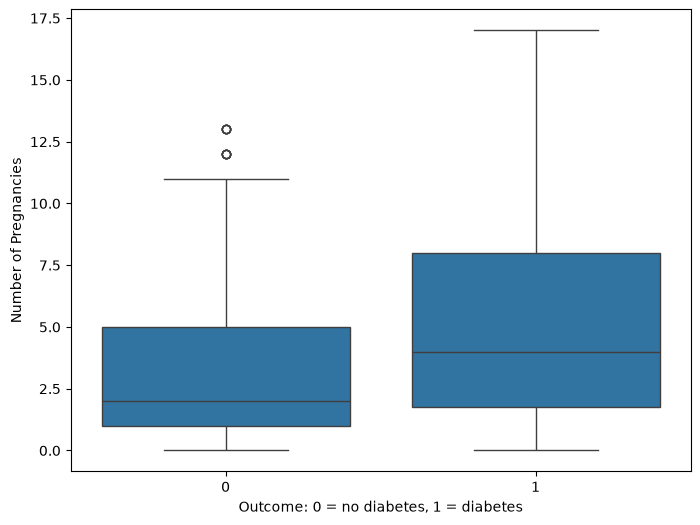

In [12]:
plt.figure(figsize=(8, 6))

sns.boxplot(x="Outcome", y="Pregnancies", data=df_clean)

plt.xlabel("Outcome: 0 = no diabetes, 1 = diabetes")
plt.ylabel("Number of Pregnancies")

In [13]:
from scipy.stats import pointbiserialr

r, p_value = pointbiserialr(df_clean["Outcome"], df_clean["Pregnancies"])

print("Correlation: ", r)
print("p-value: ", p_value)

Correlation:  0.22189815303398686
p-value:  5.065127298053726e-10


<p>
    • The results indicates a <b>statistically positive association</b>, but the association is <b>weak</b>. </br>
    • The p-value is far below common significance thresholds such as 0.05, so we can reject the null hypothesis that the population association is zero. 
</p>

### • Glucose vs Outcome

In [14]:
df_clean.groupby("Outcome")["Glucose"].agg(
    ["count", "mean", "median", "std"]
)

,count,mean,median,std
Outcome,,,,
0,497,110.643863,107.0,24.776906
1,266,142.319549,140.0,29.599199


Text(0, 0.5, 'Glucose Level (mg/dL)')

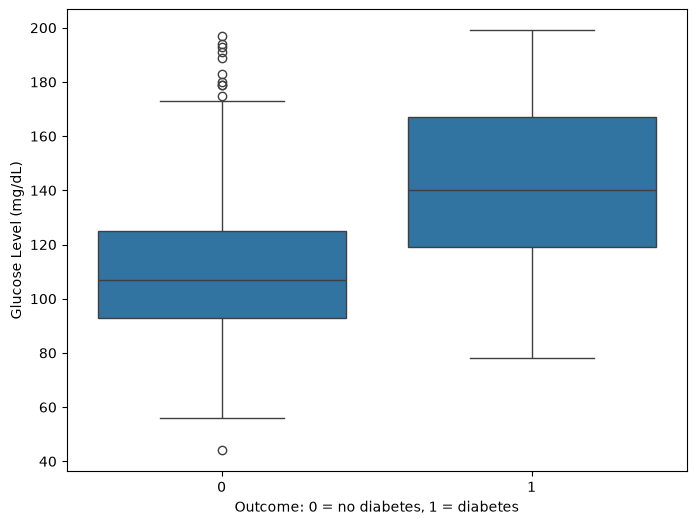

In [15]:
plt.figure(figsize=(8, 6))

sns.boxplot(x="Outcome", y="Glucose", data=df_clean)

plt.xlabel("Outcome: 0 = no diabetes, 1 = diabetes")
plt.ylabel("Glucose Level (mg/dL)")

In [16]:
from scipy.stats import pointbiserialr

correlation_data = df_clean[["Outcome", "Glucose"]].dropna()

r, p_value = pointbiserialr(
    correlation_data["Outcome"],
    correlation_data["Glucose"]
)

print("Correlation: ", r)
print("p-value: ", p_value)

Correlation:  0.4946502590810321
p-value:  2.4782891993108145e-48


<p>
    • After recording physiologically implausible glucose values of zero as missing and excluding records with missing glucose from the correlation calculation, glucose from the correlation calculation, glucose level was positively associated with diabetes outcome, 𝑟_𝑝𝑏 = 0.495, p < 0.001. This indicates that participants with diabetes (Outcome = 1) generally had higher glucose level than participants without diabetes (Outcome = 0).
</p>

### • Blood Pressure vs Outcome

In [17]:
df_clean.groupby("Outcome")["BloodPressure"].agg(
    ["count", "mean", "median", "std"]
)

,count,mean,median,std
Outcome,,,,
0,481,70.877339,70.0,12.161223
1,252,75.321429,74.5,12.299866


Text(0, 0.5, 'Blood Pressure Level (mmHg)')

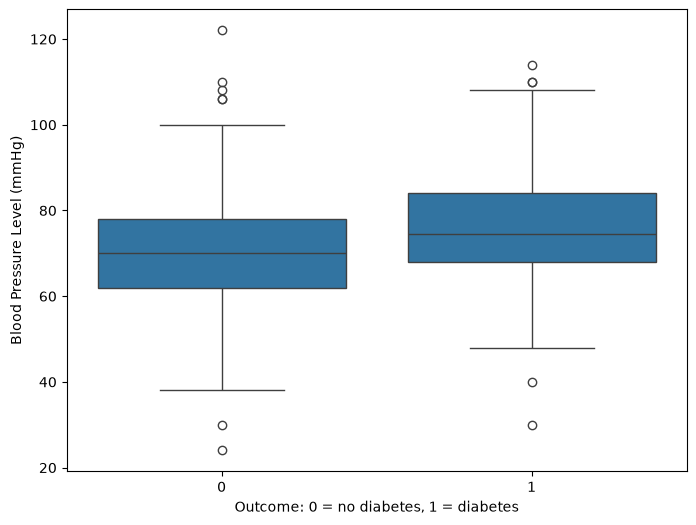

In [18]:
plt.figure(figsize=(8, 6))

sns.boxplot(x="Outcome", y="BloodPressure", data=df_clean)

plt.xlabel("Outcome: 0 = no diabetes, 1 = diabetes")
plt.ylabel("Blood Pressure Level (mmHg)")

<p>
    • Since the observations below the lower limits of the box plots are extremely low, they will be treated as outliers and replaced using median imputation.
</p>

In [19]:
# Calculate Q1 and Q3 separately for Outcome = 0 and Outcome = 1
Q1_BloodPressure = df_clean.groupby("Outcome")["BloodPressure"].transform(
    lambda x : x.quantile(0.25)
)
Q3_BloodPressure = df_clean.groupby("Outcome")["BloodPressure"].transform(
    lambda x : x.quantile(0.75)
)

# Calculate IQR and the group-specific lower limit
IQR_BloodPressure = Q3_BloodPressure - Q1_BloodPressure
LowerLimit_BP = Q1_BloodPressure - (1.5 * IQR_BloodPressure)

# Keep only observations at or above their own Outcome group's lower limit
df_clean_bp = df_clean[
    df_clean["BloodPressure"] >= LowerLimit_BP
].copy()

Text(0, 0.5, 'Blood Pressure Level (mmHg)')

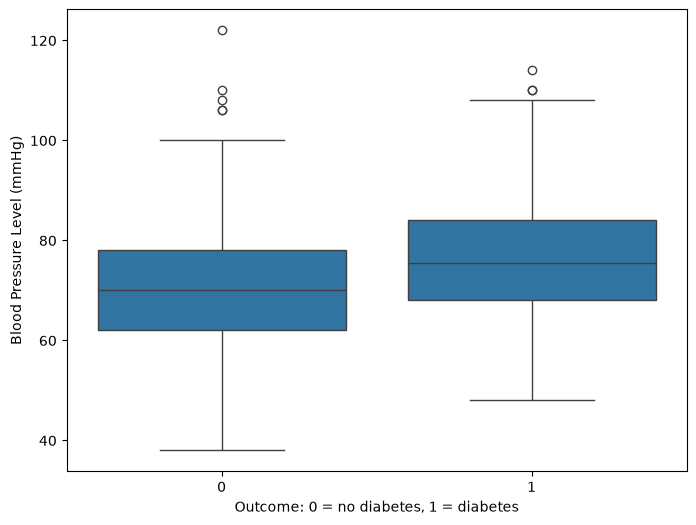

In [20]:
plt.figure(figsize=(8, 6))

sns.boxplot(x="Outcome", y="BloodPressure", data=df_clean_bp)

plt.xlabel("Outcome: 0 = no diabetes, 1 = diabetes")
plt.ylabel("Blood Pressure Level (mmHg)")

In [21]:
correlation_data = df_clean_bp[["Outcome", "BloodPressure"]].dropna()

r, p_value = pointbiserialr(
    correlation_data["Outcome"],
    correlation_data["BloodPressure"]
)

print("Correlation: ", r)
print("p-value: ", p_value)

Correlation:  0.181115767619773
p-value:  8.544554848239422e-07


<p>
    • After recoding physiologically implausible blood-pressure values of zero as missing and imputing observations below the lower boxplot limit using the median blood-pressure value, a weak but statistically significant positive association was observed between blood pressure and diabetes outcome, 𝑟_𝑝𝑏 = 0.181, p < 0.001. Participants with diabetes (Outcome = 1) generally exhibited slightly higher blood-pressure measurements than those without diabetes (Outcome = 0).
</p>

### • Skin Thickness vs Outcome

In [22]:
df_clean_bp.groupby("Outcome")["SkinThickness"].agg(
    ["count", "mean", "median", "std"]
)

,count,mean,median,std
Outcome,,,,
0,358,27.240223,27.0,10.040442
1,177,32.954802,32.0,10.389472


Text(0, 0.5, 'Skin Thickness (mm)')

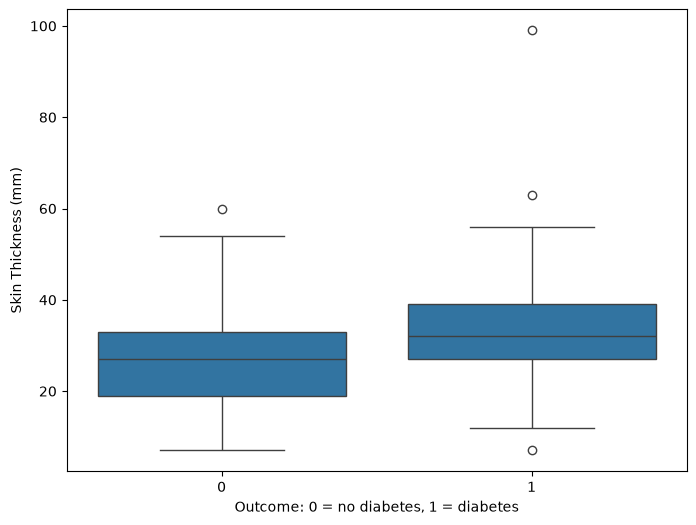

In [23]:
plt.figure(figsize=(8, 6))

sns.boxplot(x="Outcome", y="SkinThickness", data=df_clean_bp)

plt.xlabel("Outcome: 0 = no diabetes, 1 = diabetes")
plt.ylabel("Skin Thickness (mm)")

<p>
    • The observation with a value of approximately 100 can be considered an extreme value and will be replaced using the median imputation method.
</p>

In [24]:
mask_outcome_1 = df_clean_bp["Outcome"] == 1

max_skin_outcome_1 = df_clean_bp.loc[
    mask_outcome_1, "SkinThickness"
].max()

median_skin_outcome_1 = df_clean_bp.loc[
    mask_outcome_1, "SkinThickness"
].median()

df_clean_bp.loc[
    (df_clean_bp["Outcome"] == 1)
    & (df_clean_bp["SkinThickness"] == max_skin_outcome_1),
    "SkinThickness"
] = median_skin_outcome_1

Text(0, 0.5, 'Skin Thickness (mm)')

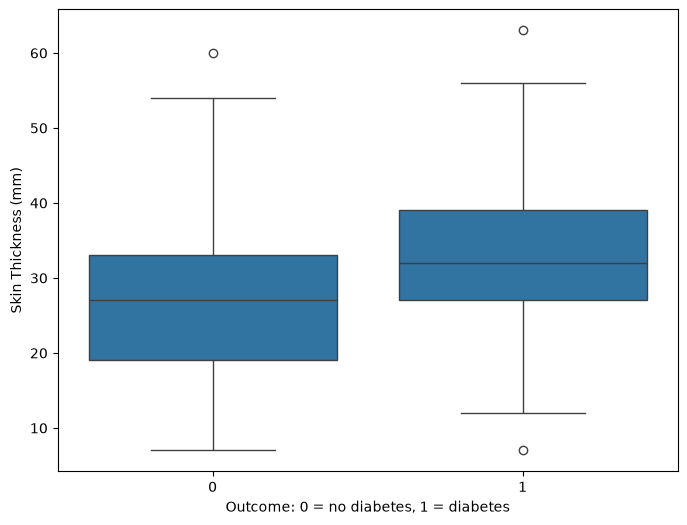

In [25]:
plt.figure(figsize=(8, 6))

sns.boxplot(x="Outcome", y="SkinThickness", data=df_clean_bp)

plt.xlabel("Outcome: 0 = no diabetes, 1 = diabetes")
plt.ylabel("Skin Thickness (mm)")

In [26]:
correlation_data = df_clean_bp[["Outcome", "SkinThickness"]].dropna()

r, p_value = pointbiserialr(
    correlation_data["Outcome"],
    correlation_data["SkinThickness"]
)

print("Correlation: ", r)
print("p-value: ", p_value)

Correlation:  0.2499670408892508
p-value:  4.5860805332110564e-09


<p>
    • After recoding zero skin-thickness values as missing and applying median imputation to the identified extreme value, a positive association was observed between skin thickness and diabetes outcome, 𝑟_𝑝𝑏 = 0.25, p < 0.001. Participants with diabetes (Outcome = 1) tended to have higher skin-thickness measurements; the association was weak to moderate in magnitude.
</p>

### • Insulin vs Outcome

In [27]:
df_clean_bp.groupby("Outcome")["Insulin"].agg(
    ["count", "mean", "median", "std"]
)

,count,mean,median,std
Outcome,,,,
0,262,130.870229,105.0,102.624106
1,128,207.992188,173.0,133.348368


Text(0, 0.5, 'Insulin Level (µU/mL)')

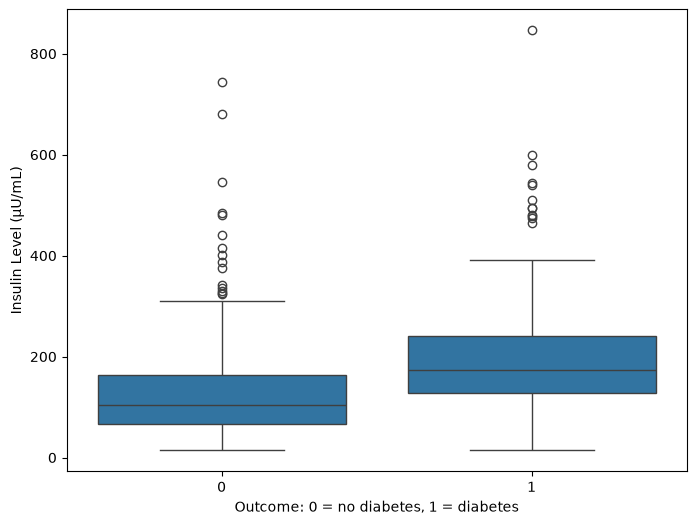

In [28]:
plt.figure(figsize=(8, 6))

sns.boxplot(x="Outcome", y="Insulin", data=df_clean_bp)

plt.xlabel("Outcome: 0 = no diabetes, 1 = diabetes")
plt.ylabel("Insulin Level (µU/mL)")

In [29]:
correlation_data = df_clean_bp[["Outcome", "Insulin"]].dropna()

r, p_value = pointbiserialr(
    correlation_data["Outcome"],
    correlation_data["Insulin"]
)

print("Correlation: ", r)
print("p-value: ", p_value)

Correlation:  0.3044320542636229
p-value:  8.300404338975717e-10


<p>
    • After recoding zero insulin values as missing and excluding records with missing insulin for the correlation analysis, insulin was moderately and positively associated with diabetes outcome, 𝑟_𝑝𝑏 = 0.304, p < 0.001. Participants with diabetes (Outcome = 1) tended to have higher recorded insulin levels than participants without diabetes.
</p>

### • BMI vs Outcome

In [30]:
df_clean_bp.groupby("Outcome")["BMI"].agg(
    ["count", "mean", "median", "std"]
)

,count,mean,median,std
Outcome,,,,
0,476,30.937815,30.4,6.546269
1,249,35.240964,34.3,6.465174


Text(0, 0.5, 'BMI (kg/m²)')

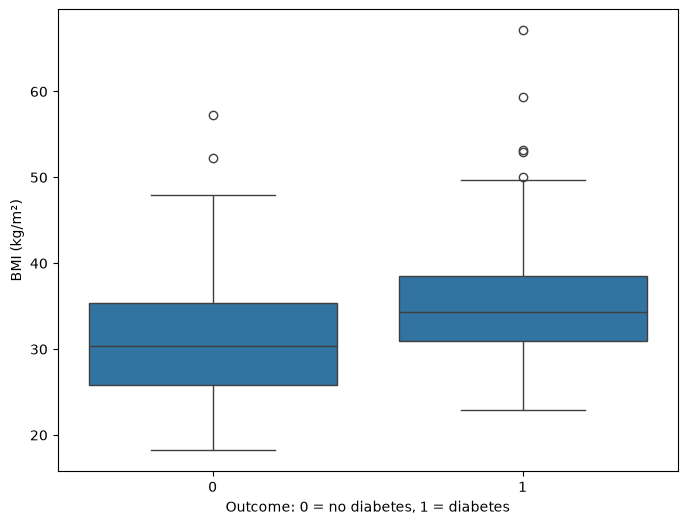

In [31]:
plt.figure(figsize=(8, 6))

sns.boxplot(x="Outcome", y="BMI", data=df_clean_bp)

plt.xlabel("Outcome: 0 = no diabetes, 1 = diabetes")
plt.ylabel("BMI (kg/m²)")

In [32]:
correlation_data = df_clean_bp[["Outcome", "BMI"]].dropna()

r, p_value = pointbiserialr(
    correlation_data["Outcome"],
    correlation_data["BMI"]
)

print("Correlation: ", r)
print("p-value: ", p_value)

Correlation:  0.2994966537539578
p-value:  1.7197411822315423e-16


<p>
    • After recoding physiologically implausible BMI values of zero as missing and excluding records with missing BMI from the correlation analysis, BMI was moderately and positively associated with diabetes outcome, 𝑟_𝑝𝑏 = 0.3, p < 0.001. Participants with diabetes (Outcome = 1) generally had higher BMI than participants without diabetes.
</p>

### • DiabetesPedigreeFunction vs Outcome

In [33]:
df_clean_bp.groupby("Outcome")["DiabetesPedigreeFunction"].agg(
    ["count", "mean", "median", "std"]
)

,count,mean,median,std
Outcome,,,,
0,479,0.433027,0.340,0.300909
1,250,0.551440,0.449,0.362841


Text(0, 0.5, 'Diabetes Pedigree Function')

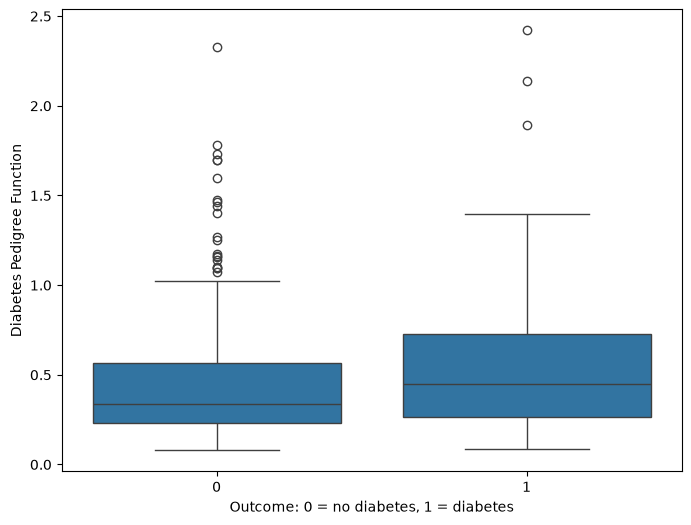

In [34]:
plt.figure(figsize=(8, 6))

sns.boxplot(x="Outcome", y="DiabetesPedigreeFunction", data=df_clean_bp)

plt.xlabel("Outcome: 0 = no diabetes, 1 = diabetes")
plt.ylabel("Diabetes Pedigree Function")

In [35]:
correlation_data = df_clean_bp[["Outcome", "DiabetesPedigreeFunction"]].dropna()

r, p_value = pointbiserialr(
    correlation_data["Outcome"],
    correlation_data["DiabetesPedigreeFunction"]
)

print("Correlation: ", r)
print("p-value: ", p_value)

Correlation:  0.17143858839899848
p-value:  3.233404941032782e-06


<p>
    • Diabetes pedigree function was weakly and positively associated with diabetes outcome, 𝑟_𝑝𝑏 = 0.171, p < 0.001. Participants with diabetes (Outcome = 1) tended to have higher diabetes-pedigree-function values than participants without diabetes.
</p>

### • Age vs Outcome

In [36]:
df_clean_bp.groupby("Outcome")["Age"].agg(
    ["count", "mean", "median", "std"]
)

,count,mean,median,std
Outcome,,,,
0,479,31.25261,27.0,11.675748
1,250,37.48400,36.0,11.124783


Text(0, 0.5, 'Age')

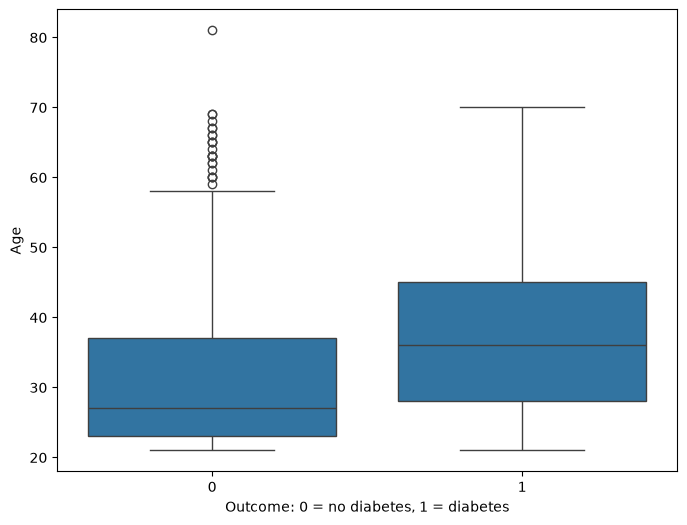

In [37]:
plt.figure(figsize=(8, 6))

sns.boxplot(x="Outcome", y="Age", data=df_clean_bp)

plt.xlabel("Outcome: 0 = no diabetes, 1 = diabetes")
plt.ylabel("Age")

In [38]:
correlation_data = df_clean_bp[["Outcome", "Age"]].dropna()

r, p_value = pointbiserialr(
    correlation_data["Outcome"],
    correlation_data["Age"]
)

print("Correlation: ", r)
print("p-value: ", p_value)

Correlation:  0.24963151813102072
p-value:  8.086069686704415e-12


<p>
    • Age was weakly to moderately and positively associated with diabetes outcome, 𝑟_𝑝𝑏 = 0.250, p < 0.001. Participants with diabetes (Outcome = 1) tended to be older than participants without diabetes.
</p>

<h1 style="color:gray"> Building the Model</h1>

In [39]:
X = df_clean_bp.drop(["Outcome"], axis=1)
X.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21
5,5,116.0,74.0,NaN,NaN,25.6,0.201,30


In [40]:
y = df_clean_bp.Outcome
y.head()

0    1
1    0
2    1
3    0
5    0
Name: Outcome, dtype: int64

In [43]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42
)

In [44]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

model = RandomForestClassifier(
    n_estimators=500, 
    random_state=42,
    class_weight="balanced"
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

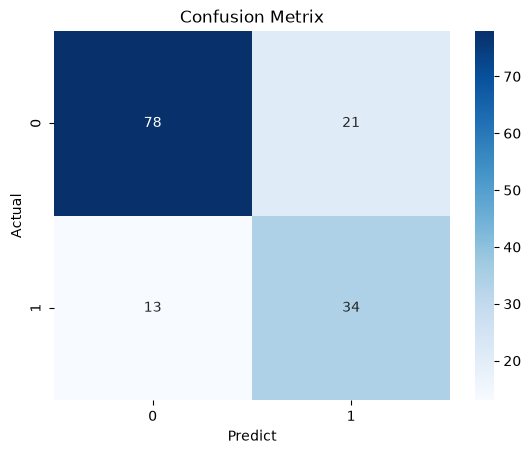

              precision    recall  f1-score   support

           0       0.86      0.79      0.82        99
           1       0.62      0.72      0.67        47

    accuracy                           0.77       146
   macro avg       0.74      0.76      0.74       146
weighted avg       0.78      0.77      0.77       146

ROC-AUC: 0.8566516226090695


In [45]:
# confusion metric
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues")
plt.title('Confusion Metrix')
plt.xlabel('Predict')
plt.ylabel('Actual')
plt.show()

# classification report
print(classification_report(y_test, y_pred))

# ROC-AUC
y_prob = model.predict_proba(X_test)[:, 1]
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

<h1 style="color:blue">Export the model to a pickle file</h1>

In [46]:
import pickle
with open("Pima_Indians_Diabetes_model.pickle","wb") as f:
    pickle.dump(model, f)